# MAML-KT

**Goal:** GRU-based DKT with projected target-item embedding fused before the readout layer. 

Training for each student:
- Support: gradient descent on $\mathcal{L}^{s}_{\text{support}}$ $\rightarrow$ $\frac{\partial \mathcal{L}_{\text{support}}}{\partial \theta}$ for meta-optimization.
- Meta-loss on query: $\theta_{s} \rightarrow \mathcal{L}^{s}_{query}$ on remaining $\rightarrow$ averaged.
- Outer-update: backpropagate through the inner updates & update the shared initialization, $\theta \leftarrow \theta - \beta \nabla_{\theta}(\frac{1}{\beta} \sum_{s=1}^{\beta} \mathcal{L}^{s}_{query})$

$\theta_{T}$ is optimized along with the query loss minimization from the adapted parameters $\theta'_{T}$ from inner loop.

$$
\min\limits_{\theta} \mathbb{E}_{\mathcal{T}\sim p(\mathcal{T})} \left[\mathcal{L}^{^\text{query}}_{\mathcal{T}} (\theta'_{\mathcal{T}}) \right]
\quad
\text{s.t.}
\quad
\theta'_{\mathcal{T}} = \theta - \alpha \nabla_{\theta} \mathcal{L}^{\text{support}}_{\mathcal{T}}(\theta)
$$

**Source to audit:** [authors' `models/maml.py`](https://github.com/Indronil-Prince/MAML-KT/blob/main/models/maml.py) and [MAML-KT paper](https://arxiv.org/html/2603.00137).

**Reproduction scope.** Paper-style (not claimed to be identical to published Table 1): the paper describes `Q3–10` and `Q11–15`, five splits, and 10/20/50 held-out students. The exact published student IDs/seeds and its support indexing are not fully specified. The authors' code counts **next-step pairs**, whereas the paper describes **raw interactions**. Here `SUPPORT_INTERACTIONS=2` means two *observed responses*, one supervised support pair, and first query Q3. To inspect the code convention, later use `SUPPORT_INTERACTIONS=3` and `INNER_STEPS=2` (first query Q4; Q3–10 cannot be fully reported).

The only lightweight check is a gradient/shape check on a *real processed student*. No simulation, no ERM, and no other KT baselines. No GitHub files are modified.

## 1. Paths and shared settings

`COHORT_SIZES` is the number of **held-out test students** (not a meta-batch). Five independently sampled student splits are used for each size. Each split gets a freshly trained MAML model. The two protocol settings are introduced only in their own training sections below.

In [1]:
import copy, json, random, sys
from collections import OrderedDict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score
from torch import nn
from torch.func import functional_call

CWD = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in (CWD, *CWD.parents)
                    if (p/'src/ktlab/data/cli.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from src.ktlab.data.cli import run_pipeline

RAW_PATH = PROJECT_ROOT / 'data/raw/ASSISTment2009.csv'
PROCESSED_DIR = PROJECT_ROOT / 'data/processed/ASSISTment2009MAML'
PROCESSED_PATH = PROCESSED_DIR / 'ASSISTment2009MAML.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs/maml/ASSISTment2009'
EDA_DIR = OUTPUT_DIR / 'eda'

SEED = 42
MIN_STUDENT_INTERACTIONS = 20
EMBEDDING_DIM, HIDDEN_DIM = 128, 256
INNER_LR, OUTER_LR = 0.005, 0.001
META_BATCH_SIZE, EPOCHS = 16, 10
COHORT_SIZES = (10, 20, 50)
SPLIT_COUNT = 5

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.enabled = False  # Second-order GRU derivatives on CUDA
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
for folder in (PROCESSED_DIR, EDA_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT_ROOT)
print('Device:', DEVICE, '| cohorts:', COHORT_SIZES, '| splits:', SPLIT_COUNT)

Project: C:\Users\Dell ProMax Tower T2\Downloads\code\kt-state-lab
Device: cpu | cohorts: (10, 20, 50) | splits: 5


## 2. Examine the raw file

ASSIST2009 can have several CSV rows describing one attempt when multiple skill annotations exist. These plots distinguish raw rows from unique interactions.

Source rows: 525534 | students: 4217 | questions: 26688


,order_id,assignment_id,user_id,assistment_id,problem_id,original,correct,attempt_count,ms_first_response,tutor_mode,...,hint_count,hint_total,overlap_time,template_id,answer_id,answer_text,first_action,bottom_hint,opportunity,opportunity_original
0,33022537,277618,64525,33139,51424,1,1,1,32454,tutor,...,0,3,32454,30799,NaN,26,0,NaN,1,1
1,33022709,277618,64525,33150,51435,1,1,1,4922,tutor,...,0,3,4922,30799,NaN,55,0,NaN,2,2
2,35450204,220674,70363,33159,51444,1,0,2,25390,tutor,...,0,3,42000,30799,NaN,88,0,NaN,1,1
3,35450295,220674,70363,33110,51395,1,1,1,4859,tutor,...,0,3,4859,30059,NaN,41,0,NaN,2,2
4,35450311,220674,70363,33196,51481,1,0,14,19813,tutor,...,3,4,124564,30060,NaN,65,0,0,3,3


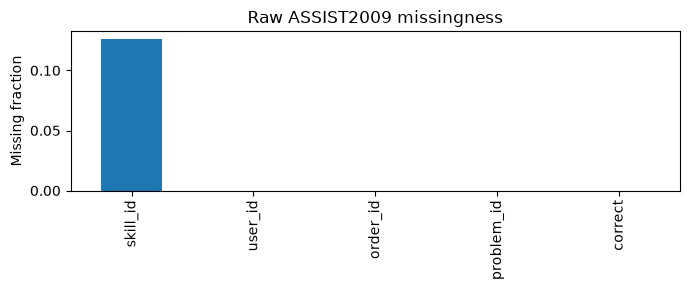

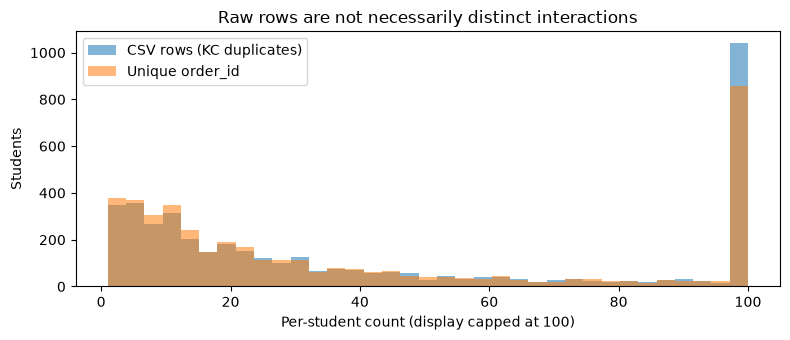

In [2]:
raw = pd.read_csv(RAW_PATH, dtype=str, low_memory=False, encoding='cp1252')
print('Source rows:', len(raw), '| students:', raw.user_id.nunique(),
      '| questions:', raw.problem_id.nunique())
display(raw.head())

fields = ['user_id', 'order_id', 'problem_id', 'skill_id', 'correct']
missing = raw[fields].isna().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 3))
missing.plot.bar(ax=ax)
ax.set_ylabel('Missing fraction')
ax.set_title('Raw ASSIST2009 missingness')
fig.tight_layout()
fig.savefig(EDA_DIR/'raw_missingness.png', dpi=200, bbox_inches='tight')
plt.show()

raw_rows = raw.groupby('user_id').size()
raw_interactions = raw.groupby('user_id')['order_id'].nunique()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(raw_rows.clip(upper=100), bins=35, alpha=.55,
        label='CSV rows (KC duplicates)')
ax.hist(raw_interactions.clip(upper=100), bins=35, alpha=.55,
        label='Unique order_id')
ax.set(xlabel='Per-student count (display capped at 100)', ylabel='Students',
       title='Raw rows are not necessarily distinct interactions')
ax.legend()
fig.tight_layout()
fig.savefig(EDA_DIR/'raw_rows_vs_interactions.png', dpi=200,
            bbox_inches='tight')
plt.show()

## 3. Consolidate interactions

We combine rows that share a student and `order_id`, preserve chronological order, and retain students with at least 20 interactions. The missing-KC filter follows our earlier processing, although the GRU itself uses question IDs and correctness, not KC IDs. This difference matters when comparing against the authors' processed data.

In [3]:
clean = raw.dropna(subset=['user_id', 'order_id', 'problem_id', 'skill_id', 'correct']).copy()
clean['correct'] = pd.to_numeric(clean['correct'], errors='coerce')
clean['order_number'] = pd.to_numeric(clean['order_id'], errors='coerce')
clean = clean[clean.correct.isin([0, 1]) & clean.order_number.notna()].copy()
clean = clean.sort_values(['user_id', 'order_number'], kind='stable')

conflict_counts = clean.groupby(['user_id', 'order_id'])[['problem_id', 'correct']].nunique()
conflicts = int(conflict_counts.gt(1).any(axis=1).sum())
print('Conflicting question/answer groups:', conflicts)
if conflicts:
    raise ValueError('Conflicting interaction labels; inspect raw rows before aggregating')

processed = clean.groupby(['user_id', 'order_id'], sort=False, as_index=False).agg(
    question_id=('problem_id', 'first'), correct=('correct', 'first'),
    order_number=('order_number', 'first'),
    kc_ids=('skill_id', lambda values: ';'.join(dict.fromkeys(
        kc for value in values for kc in value.split('_') if kc
    )))
)
processed = processed.rename(columns={'user_id':'student_id', 'order_id':'interaction_id'})
processed = processed.sort_values(['student_id', 'order_number'], kind='stable')
lengths = processed.groupby('student_id')['student_id'].transform('size')
processed = processed[lengths >= MIN_STUDENT_INTERACTIONS].copy()
processed['step'] = processed.groupby('student_id').cumcount() + 1
processed['timestamp'] = ''; processed['question_text'] = ''
processed = processed[['student_id', 'interaction_id', 'step', 'question_id',
                       'kc_ids', 'correct', 'timestamp', 'question_text']]
processed.to_csv(PROCESSED_PATH, index=False)

conversion = pd.DataFrame([{
    'raw_csv_rows': len(raw), 'rows_after_missing_and_label_filter': len(clean),
    'unique_interactions_before_length_filter': len(conflict_counts),
    'processed_interactions': len(processed),
    'processed_students': processed.student_id.nunique(),
    'merged_extra_kc_annotation_rows': len(clean) - len(conflict_counts),
    'conflicting_groups': conflicts
}])
conversion.to_csv(PROCESSED_DIR/'conversion_summary.csv', index=False)
display(conversion)

manifest = run_pipeline(PROCESSED_PATH, PROCESSED_DIR, seed=SEED,
                        support_sizes=(2, 3))
print('Student splits:', manifest['counts']['students'])

Conflicting question/answer groups: 0


,raw_csv_rows,rows_after_missing_and_label_filter,unique_interactions_before_length_filter,processed_interactions,processed_students,merged_extra_kc_annotation_rows,conflicting_groups
0,525534,459208,283105,265502,2131,176103,0


Student splits: {'train': 1705, 'val': 213, 'test': 213}


## 4. EDA for the cold-start setting

The teammate pipeline's initial 80/10/10 split is used only for EDA; the **experiment-specific held-out cohorts are sampled later**. Figures are saved separately under `outputs/maml/ASSISTment2009/eda/`.

,split,students,interactions,mean_correct,eligible_for_K
0,train,1705,219017,0.658383,1705
1,val,213,22619,0.667138,213
2,test,213,23866,0.656918,213


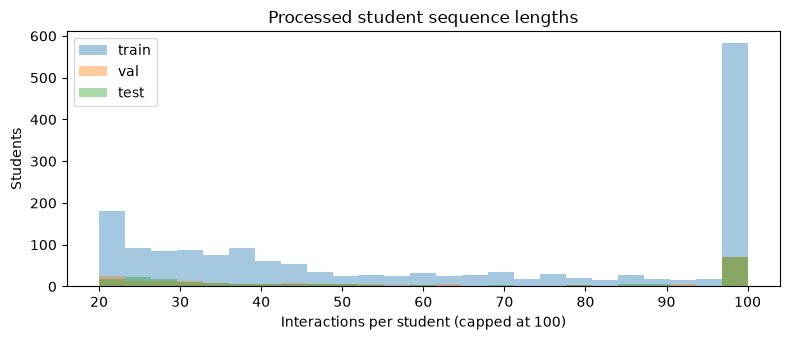

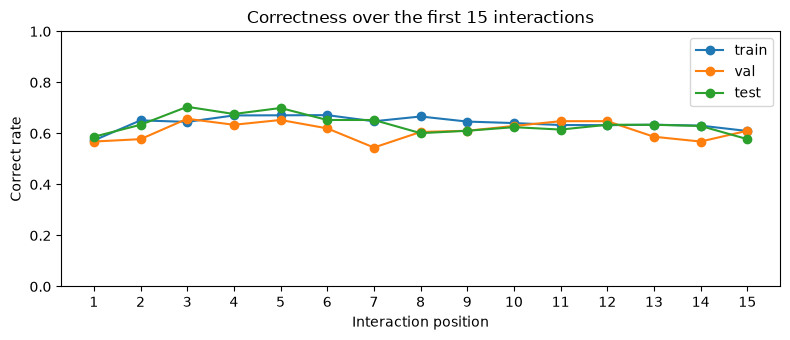

split,test,train,val
K,,,
2,213,1705,213
3,213,1705,213
5,213,1705,213
10,213,1705,213


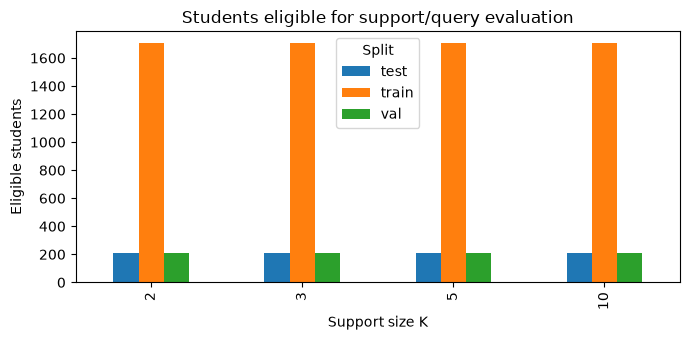

Saved EDA files:
 - outputs\maml\ASSISTment2009\eda\early_correctness_by_position.png
 - outputs\maml\ASSISTment2009\eda\processed_eda.png
 - outputs\maml\ASSISTment2009\eda\processed_sequence_lengths.png
 - outputs\maml\ASSISTment2009\eda\raw_missingness.png
 - outputs\maml\ASSISTment2009\eda\raw_rows_vs_interactions.png
 - outputs\maml\ASSISTment2009\eda\raw_sequence_lengths.png
 - outputs\maml\ASSISTment2009\eda\split_summary.csv
 - outputs\maml\ASSISTment2009\eda\support_coverage.csv
 - outputs\maml\ASSISTment2009\eda\support_coverage.png


In [4]:
SPLIT_DIR = PROCESSED_DIR / 'splits'
splits = {part: pd.read_csv(SPLIT_DIR/f'{part}.csv',
    dtype={'student_id':str, 'question_id':str, 'kc_ids':str})
    for part in ('train', 'val', 'test')}

summary = pd.DataFrame([{
    'split':part, 'students':frame.student_id.nunique(),
    'interactions':len(frame), 'mean_correct':frame.correct.mean(),
    'eligible_for_K':int((frame.groupby('student_id').size() > 2).sum())
} for part,frame in splits.items()])
display(summary)
summary.to_csv(EDA_DIR/'split_summary.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
for part, frame in splits.items():
    length = frame.groupby('student_id').size()
    ax.hist(length.clip(upper=100), bins=25, alpha=.4, label=part)
ax.set(xlabel='Interactions per student (capped at 100)', ylabel='Students', title='Processed student sequence lengths')
ax.legend()
fig.tight_layout()
fig.savefig(EDA_DIR/'processed_sequence_lengths.png', dpi=200, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
for part, frame in splits.items():
    early = frame[frame.step.between(1, 15)].groupby('step').correct.mean()
    ax.plot(early.index, early.values, marker='o', label=part)
ax.set(xlabel='Interaction position', ylabel='Correct rate',
       title='Correctness over the first 15 interactions', ylim=(0, 1))
ax.set_xticks(range(1, 16))
ax.legend()
fig.tight_layout()
fig.savefig(EDA_DIR/'early_correctness_by_position.png', dpi=200,
            bbox_inches='tight')
plt.show()

coverage = pd.DataFrame([{
    'split':part, 'K':k,
    'eligible_students':int((frame.groupby('student_id').size() > k).sum())
} for part,frame in splits.items() for k in (2, 3, 5, 10)])
coverage_table = coverage.pivot(index='K', columns='split', values='eligible_students')
display(coverage_table)
coverage.to_csv(EDA_DIR/'support_coverage.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
coverage_table.plot.bar(ax=ax)
ax.set(xlabel='Support size K', ylabel='Eligible students', title='Students eligible for support/query evaluation')
ax.legend(title='Split')
fig.tight_layout()
fig.savefig(EDA_DIR/'support_coverage.png', dpi=200, bbox_inches='tight')
plt.show()

print('Saved EDA files:')
for file in sorted(EDA_DIR.glob('*')):
    print(' -', file.relative_to(PROJECT_ROOT))

## 5. Construct next-step tasks

A prediction at question $q_{t+1}$ uses the observed interaction $(q_t,a_t)$ and target question $q_{t+1}$. The model receives **no future answer**.

- **Paper-style:** Q1 and Q2 are observed, giving one supervised support pair, Q1 $\to$ Q2. The first query target is Q3.
- **Repo-style:** two supervised support pairs, Q1 $\to$ Q2 and Q2 $\to$ Q3. The first query target is Q4.

The first answer Q1 cannot itself be a next-step training target without adding a special start token, which the authors' GRU does not use. As in the released code, the GRU starts a fresh hidden state for the query suffix. Support affects query predictions through the updated parameters.

In [5]:
class DKTGRU(nn.Module):
    def __init__(self, num_questions, embedding_dim, hidden_dim):
        super().__init__()
        self.interaction_embedding = nn.Embedding(2*num_questions, embedding_dim, padding_idx=0)
        self.question_embedding = nn.Embedding(num_questions, embedding_dim, padding_idx=0)
        self.gru = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.target_projection = nn.Linear(embedding_dim, hidden_dim)
        self.head = nn.Linear(hidden_dim, 1)

    def forward(self, interactions, target_questions):
        hidden, _ = self.gru(self.interaction_embedding(interactions))
        target = self.target_projection(self.question_embedding(target_questions))
        return self.head(hidden + target).squeeze(-1)


def make_tasks(frame, vocabulary, num_questions, support_observations):
    tasks = []
    for student, history in frame.groupby('student_id', sort=False):
        history = history.sort_values('step')
        questions = np.array([vocabulary.get(str(q), 1) for q in history.question_id], dtype=np.int64)
        labels = history.correct.to_numpy(dtype=np.int64)
        interactions = torch.tensor(questions[:-1] + num_questions*labels[:-1], device=DEVICE)
        next_questions = torch.tensor(questions[1:], device=DEVICE)
        next_labels = torch.tensor(labels[1:], dtype=torch.float32, device=DEVICE)
        boundary = support_observations - 1

        known = set()
        first_seen = []
        for kcs in history.kc_ids:
            current = set(str(kcs).split(';'))
            first_seen.append(bool(current - known))
            known.update(current)

        tasks.append({
            'student_id': student,
            'support': (interactions[:boundary], next_questions[:boundary], next_labels[:boundary]),
            'query': (interactions[boundary:], next_questions[boundary:], next_labels[boundary:]),
            'positions': list(range(support_observations+1, len(history)+1)),
            'new_student_kc': first_seen[support_observations:]
        })
    return tasks

## 6. MAML, predictions, and metrics

A student-specific update is $\theta' = \theta - \alpha\nabla_\theta L_{support}(\theta)$. The outer optimizer minimizes the mean query loss across student tasks and differentiates through each inner update.

We record **pooled accuracy and AUC** (the metrics used in the authors' script), along with paper-style **position-averaged accuracy**, BCE, and Brier score. AUC is undefined when the evaluated labels contain only one class; those cases are stored as `NaN`.

In [6]:
def loss_for(model, params, pairs):
    interactions, questions, labels = pairs
    logits = functional_call(model, params, (interactions[None, :], questions[None, :]))[0]
    return nn.functional.binary_cross_entropy_with_logits(logits, labels)


def adapt(model, support, inner_steps, second_order):
    fast = OrderedDict(model.named_parameters())
    for _ in range(inner_steps):
        loss = loss_for(model, fast, support)
        gradients = torch.autograd.grad(loss, tuple(fast.values()), create_graph=second_order)
        fast = OrderedDict((name, value-INNER_LR*grad) for (name, value), grad in zip(fast.items(), gradients))
    return fast


def train_epoch(model, optimizer, tasks, epoch, seed, inner_steps):
    model.train()
    order = list(range(len(tasks)))
    random.Random(seed+epoch).shuffle(order)
    losses = []
    for start in range(0, len(order), META_BATCH_SIZE):
        optimizer.zero_grad()
        batch = [tasks[i] for i in order[start:start+META_BATCH_SIZE]]
        query_losses = [loss_for(model, adapt(model, t['support'], inner_steps, True), t['query']) for t in batch]
        torch.stack(query_losses).mean().backward()
        optimizer.step()
        losses.extend(float(l.detach()) for l in query_losses)
    return float(np.mean(losses))


def predict(model, tasks, inner_steps):
    model.eval()
    rows = []
    for task in tasks:
        with torch.enable_grad():
            adapted = adapt(model, task['support'], inner_steps, False)
        initial = OrderedDict(model.named_parameters())
        query = task['query']
        inputs = (query[0][None, :], query[1][None, :])
        with torch.no_grad():
            before = functional_call(model, initial, inputs).sigmoid()[0].cpu().numpy()
            after = functional_call(model, adapted, inputs).sigmoid()[0].cpu().numpy()
        for pos, label, p0, p1, novel in zip(
            task['positions'], query[2].cpu().numpy(), before, after, task['new_student_kc']):
            rows.append({'student_id': task['student_id'], 'position': pos,
                'correct': int(label), 'p_before': float(p0), 'p_after': float(p1),
                'new_student_kc': bool(novel)})
    return pd.DataFrame(rows)


def scores(pred, column):
    y = pred.correct.to_numpy(dtype=np.int64)
    p = pred[column].to_numpy(dtype=float).clip(1e-7, 1-1e-7)
    auc = roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
    return {'pooled_accuracy': float(np.mean((p >= 0.5) == y)),
        'auc': float(auc),
        'bce': float(np.mean(-(y*np.log(p)+(1-y)*np.log(1-p)))),
        'brier': float(np.mean((p-y)**2)),
        'responses': len(pred), 'students': pred.student_id.nunique()}


def window_scores(pred, column, first, last):
    d = pred[pred.position.between(first, last)].copy()
    d['hit'] = (d[column] >= 0.5) == d.correct
    return {'position_avg_accuracy': float(d.groupby('position').hit.mean().mean()),
        'position_count': d.position.nunique(), **scores(d, column)}

## 7. A short gradient check on a real student

This only checks the support boundary and that query gradients reach the global model. It does not train a replacement model on artificial examples.

In [7]:
student_id = sorted(processed.student_id.unique())[0]
example = processed[processed.student_id == student_id]
example_vocab = {str(q): i+2 for i, q in enumerate(sorted(example.question_id.unique()))}
for mode, observed, steps in [('paper', 2, 1), ('repo', 3, 2)]:
    task = make_tasks(example, example_vocab, len(example_vocab)+2, observed)[0]
    model_check = DKTGRU(len(example_vocab)+2, 8, 16).to(DEVICE)
    loss = loss_for(model_check, adapt(model_check, task['support'], steps, True), task['query'])
    grads = torch.autograd.grad(loss, tuple(model_check.parameters()))
    grad_norm = torch.linalg.vector_norm(torch.stack([g.norm() for g in grads]))
    print(mode, '| support pairs:', task['support'][2].numel(),
          '| first query: Q'+str(task['positions'][0]),
          '| meta-gradient norm:', float(grad_norm))

paper | support pairs: 1 | first query: Q3 | meta-gradient norm: 0.33241862058639526
repo | support pairs: 2 | first query: Q4 | meta-gradient norm: 0.2603265345096588


## 8. Sample held-out cohorts

For each cohort size and split, we **randomly permute eligible student IDs** with a recorded seed. The first 10/20/50 IDs form the test cohort; about 10% of the remaining students form validation; the rest are meta-training students. No student appears in multiple roles **within a split**. Test cohorts in different splits may overlap. Both modes reuse the same sampled IDs, so the comparison is paired by split.

The split is student-disjoint, and question IDs are integer-encoded using **training students only** (`0=PAD`, `1=UNK`).

In [8]:
def prepare_split(cohort_size, split_number, support_observations):
    seed = SEED + 1000*cohort_size + split_number
    students = np.array(sorted(processed.student_id.astype(str).unique()))
    shuffled = np.random.default_rng(seed).permutation(students)
    val_count = round(0.1*(len(shuffled)-cohort_size))
    roles = pd.DataFrame({'student_id': shuffled,
        'role': ['test']*cohort_size + ['val']*val_count + ['train']*(len(shuffled)-cohort_size-val_count)})
    frames = {role: processed[processed.student_id.isin(
        roles.loc[roles.role.eq(role), 'student_id'])].copy()
        for role in ('train', 'val', 'test')}
    vocabulary = {str(q): i+2 for i, q in enumerate(sorted(frames['train'].question_id.unique()))}
    num_questions = len(vocabulary)+2
    tasks = {role: make_tasks(frame, vocabulary, num_questions, support_observations)
             for role, frame in frames.items()}
    return seed, roles, tasks, num_questions

## 9. Training runner shared by both modes

This function handles exactly the same cohort sampling, model, optimizer, and metrics for each mode. Only the support boundary, number of inner updates, and checkpoint rule differ. Every split writes its student IDs, configuration, checkpoint, training history, and test predictions.

In [9]:
def run_mode(mode, support_observations, inner_steps, checkpoint_rule):
    mode_dir = OUTPUT_DIR / mode
    mode_dir.mkdir(parents=True, exist_ok=True)
    split_rows, position_rows, epoch_rows, prefix_rows, student_rows, kc_rows = [], [], [], [], [], []
    first_query = support_observations + 1
    critical_name = 'critical_Q3_Q10' if first_query == 3 else 'partial_critical_Q4_Q10'

    for cohort_size in COHORT_SIZES:
        for split_number in range(1, SPLIT_COUNT+1):
            seed, roles, tasks, num_questions = prepare_split(cohort_size, split_number, support_observations)
            folder = mode_dir / f'cohort_{cohort_size}' / f'split_{split_number}'
            folder.mkdir(parents=True, exist_ok=True)
            roles.to_csv(folder/'students.csv', index=False)

            torch.manual_seed(seed)
            model = DKTGRU(num_questions, EMBEDDING_DIM, HIDDEN_DIM).to(DEVICE)
            optimizer = torch.optim.Adam(model.parameters(), lr=OUTER_LR, weight_decay=1e-4)
            best_acc, best_state, chosen_epoch = -np.inf, None, EPOCHS
            print(f'{mode} | cohort {cohort_size}, split {split_number} |',
                  {role: len(task_list) for role, task_list in tasks.items()})

            for epoch in range(1, EPOCHS+1):
                train_bce = train_epoch(model, optimizer, tasks['train'], epoch, seed, inner_steps)
                record = {'cohort_size': cohort_size, 'split': split_number,
                          'epoch': epoch, 'train_query_bce': train_bce,
                          'val_query_bce': np.nan, 'val_early_accuracy': np.nan}
                if checkpoint_rule == 'validation':
                    val = predict(model, tasks['val'], inner_steps)
                    record['val_query_bce'] = scores(val, 'p_after')['bce']
                    score = window_scores(val, 'p_after', first_query, 10)['position_avg_accuracy']
                    record['val_early_accuracy'] = score
                    if score > best_acc:
                        best_acc = score
                        best_state = copy.deepcopy(model.state_dict())
                        chosen_epoch = epoch
                epoch_rows.append(record)
                print(f'  epoch {epoch:02d}: train BCE {train_bce:.4f}' +
                      (f", val early {record['val_early_accuracy']:.4f}" if checkpoint_rule == 'validation' else ''))

            if checkpoint_rule == 'validation':
                model.load_state_dict(best_state)
            else:
                best_state = copy.deepcopy(model.state_dict())
            test = predict(model, tasks['test'], inner_steps)
            test.to_csv(folder/'predictions.csv', index=False)
            torch.save(best_state, folder/'model.pt')
            with (folder/'config.json').open('w', encoding='utf-8') as file:
                json.dump({'mode': mode, 'cohort_size': cohort_size,
                    'split': split_number, 'seed': seed, 'support_observations': support_observations,
                    'support_supervised_pairs': support_observations-1,
                    'first_query_position': first_query, 'inner_steps': inner_steps,
                    'inner_lr': INNER_LR, 'outer_lr': OUTER_LR,
                    'epochs': EPOCHS, 'meta_batch': META_BATCH_SIZE,
                    'embedding_dim': EMBEDDING_DIM, 'hidden_dim': HIDDEN_DIM,
                    'checkpoint_rule': checkpoint_rule, 'chosen_epoch': chosen_epoch,
                    'train_students': len(tasks['train']), 'val_students': len(tasks['val']),
                    'test_students': len(tasks['test'])}, file, indent=2)

            windows = [(critical_name, first_query, 10),
                       ('common_Q4_Q10', 4, 10),
                       ('moderate_Q11_Q15', 11, 15),
                       ('full_query', first_query, int(test.position.max()))]
            for window, lo, hi in windows:
                for stage, col in [('before', 'p_before'), ('after', 'p_after')]:
                    split_rows.append({'cohort_size': cohort_size, 'split': split_number,
                        'adaptation': stage, 'window': window,
                        **window_scores(test, col, lo, hi)})

            for end_pos in range(first_query, 21):
                for stage, col in [('before', 'p_before'), ('after', 'p_after')]:
                    prefix_rows.append({'cohort_size': cohort_size, 'split': split_number,
                        'adaptation': stage, 'end_position': end_pos,
                        **window_scores(test, col, first_query, end_pos)})

            early = test[test.position.between(first_query, 20)].copy()
            early['hit_before'] = (early.p_before >= .5) == early.correct
            early['hit_after'] = (early.p_after >= .5) == early.correct
            early['brier_improvement'] = ((early.p_before-early.correct)**2 - (early.p_after-early.correct)**2)
            for position, group in early.groupby('position'):
                position_rows.append({'cohort_size': cohort_size, 'split': split_number,
                    'position': position, 'accuracy_before': group.hit_before.mean(),
                    'accuracy_after': group.hit_after.mean(),
                    'brier_improvement': group.brier_improvement.mean(),
                    'students': group.student_id.nunique()})
            for student, group in early.groupby('student_id'):
                student_rows.append({'cohort_size': cohort_size, 'split': split_number,
                    'student_id': student, 'brier_improvement': group.brier_improvement.mean(),
                    'responses': len(group)})
            for novel, group in early.groupby('new_student_kc'):
                kc_rows.append({'cohort_size': cohort_size, 'split': split_number,
                    'new_student_kc': novel, 'brier_improvement': group.brier_improvement.mean(),
                    'responses': len(group)})

    tables = {
        'split_results': pd.DataFrame(split_rows),
        'position_results': pd.DataFrame(position_rows),
        'history': pd.DataFrame(epoch_rows),
        'prefix_metrics': pd.DataFrame(prefix_rows),
        'student_adaptation': pd.DataFrame(student_rows),
        'kc_diagnostics': pd.DataFrame(kc_rows)
    }
    tables['summary'] = tables['split_results'].groupby(
        ['cohort_size', 'adaptation', 'window']).agg(
        position_avg_accuracy=('position_avg_accuracy', 'mean'),
        accuracy_std=('position_avg_accuracy', 'std'),
        pooled_accuracy=('pooled_accuracy', 'mean'),
        auc=('auc', 'mean'), bce=('bce', 'mean'), brier=('brier', 'mean'),
        splits=('split', 'nunique')).reset_index()
    for name, table in tables.items():
        table.to_csv(mode_dir/f'{name}.csv', index=False)
    display(tables['summary'].round(4))
    return tables

## 10. Paper-style run — observed Q1 and Q2

This trains all cohort/split combinations, selecting checkpoints on validation Q3–10 accuracy. The saved predictions begin at Q3. No configuration switch is needed before the next section.

In [10]:
paper_results = run_mode(mode='paper', support_observations=2, inner_steps=1, checkpoint_rule='validation')

paper | cohort 10, split 1 | {'train': 1909, 'val': 212, 'test': 10}
  epoch 01: train BCE 0.6701, val early 0.6445
  epoch 02: train BCE 0.6593, val early 0.6427
  epoch 03: train BCE 0.6536, val early 0.6574
  epoch 04: train BCE 0.6430, val early 0.6557
  epoch 05: train BCE 0.6342, val early 0.6515
  epoch 06: train BCE 0.6218, val early 0.6686
  epoch 07: train BCE 0.6109, val early 0.6580
  epoch 08: train BCE 0.5999, val early 0.6580
  epoch 09: train BCE 0.5900, val early 0.6562
  epoch 10: train BCE 0.5808, val early 0.6545
paper | cohort 10, split 2 | {'train': 1909, 'val': 212, 'test': 10}
  epoch 01: train BCE 0.6687, val early 0.6291
  epoch 02: train BCE 0.6559, val early 0.6403
  epoch 03: train BCE 0.6483, val early 0.6368
  epoch 04: train BCE 0.6372, val early 0.6380
  epoch 05: train BCE 0.6255, val early 0.6380
  epoch 06: train BCE 0.6138, val early 0.6374
  epoch 07: train BCE 0.6043, val early 0.6456
  epoch 08: train BCE 0.5966, val early 0.6356
  epoch 09: trai

,cohort_size,adaptation,window,position_avg_accuracy,accuracy_std,pooled_accuracy,auc,bce,brier,splits
0,10,after,common_Q4_Q10,0.7143,0.0440,0.7143,0.5943,0.6062,0.2082,5
1,10,after,critical_Q3_Q10,0.7225,0.0582,0.7225,0.5826,0.6063,0.2080,5
2,10,after,full_query,0.6951,0.1221,0.6865,0.5854,0.6092,0.2097,5
3,10,after,moderate_Q11_Q15,0.6640,0.0754,0.6640,0.6191,0.6230,0.2164,5
4,10,before,common_Q4_Q10,0.7086,0.0540,0.7086,0.5918,0.6066,0.2083,5
5,10,before,critical_Q3_Q10,0.7175,0.0677,0.7175,0.5806,0.6067,0.2082,5
6,10,before,full_query,0.6947,0.1224,0.6847,0.5844,0.6096,0.2099,5
7,10,before,moderate_Q11_Q15,0.6640,0.0754,0.6640,0.6207,0.6225,0.2162,5
8,20,after,common_Q4_Q10,0.6829,0.0644,0.6829,0.6437,0.6162,0.2130,5
9,20,after,critical_Q3_Q10,0.6862,0.0608,0.6862,0.6299,0.6168,0.2133,5


## 11. Repo-style run — two next-step pairs and two inner updates

This retrains on the **same cohort/split IDs** as the paper-style run. The authors' script uses its final epoch, so we do the same. Saved query predictions begin at Q4.

In [11]:
repo_results = run_mode(mode='repo', support_observations=3, inner_steps=2, checkpoint_rule='final')

repo | cohort 10, split 1 | {'train': 1909, 'val': 212, 'test': 10}
  epoch 01: train BCE 0.6701
  epoch 02: train BCE 0.6590
  epoch 03: train BCE 0.6495
  epoch 04: train BCE 0.6367
  epoch 05: train BCE 0.6253
  epoch 06: train BCE 0.6132
  epoch 07: train BCE 0.6054
  epoch 08: train BCE 0.5921
  epoch 09: train BCE 0.5835
  epoch 10: train BCE 0.5728
repo | cohort 10, split 2 | {'train': 1909, 'val': 212, 'test': 10}
  epoch 01: train BCE 0.6688
  epoch 02: train BCE 0.6562
  epoch 03: train BCE 0.6471
  epoch 04: train BCE 0.6348
  epoch 05: train BCE 0.6245
  epoch 06: train BCE 0.6123
  epoch 07: train BCE 0.6030
  epoch 08: train BCE 0.5930
  epoch 09: train BCE 0.5823
  epoch 10: train BCE 0.5726
repo | cohort 10, split 3 | {'train': 1909, 'val': 212, 'test': 10}
  epoch 01: train BCE 0.6683
  epoch 02: train BCE 0.6579
  epoch 03: train BCE 0.6485
  epoch 04: train BCE 0.6367
  epoch 05: train BCE 0.6275
  epoch 06: train BCE 0.6162
  epoch 07: train BCE 0.6049
  epoch 08: t

,cohort_size,adaptation,window,position_avg_accuracy,accuracy_std,pooled_accuracy,auc,bce,brier,splits
0,10,after,common_Q4_Q10,0.6400,0.0445,0.6400,0.5338,0.6219,0.2163,5
1,10,after,full_query,0.6796,0.1245,0.6796,0.6099,0.6224,0.2141,5
2,10,after,moderate_Q11_Q15,0.6600,0.0748,0.6600,0.6315,0.6447,0.2245,5
3,10,after,partial_critical_Q4_Q10,0.6400,0.0445,0.6400,0.5338,0.6219,0.2163,5
4,10,before,common_Q4_Q10,0.6343,0.0568,0.6343,0.5363,0.6230,0.2168,5
5,10,before,full_query,0.6754,0.1250,0.6756,0.6084,0.6244,0.2151,5
6,10,before,moderate_Q11_Q15,0.6600,0.0748,0.6600,0.6340,0.6449,0.2245,5
7,10,before,partial_critical_Q4_Q10,0.6343,0.0568,0.6343,0.5363,0.6230,0.2168,5
8,20,after,common_Q4_Q10,0.6829,0.0387,0.6829,0.6580,0.6127,0.2114,5
9,20,after,full_query,0.6734,0.0841,0.6691,0.6286,0.6404,0.2213,5


## 12. Results for each mode

Each mode gets its own figures: training curves, question-position accuracy with sample counts, Brier improvement, and performance by test cohort size. We also record how adaptation affects individual students and first-seen KCs. A positive Brier improvement means the adapted prediction is closer to the true answer.

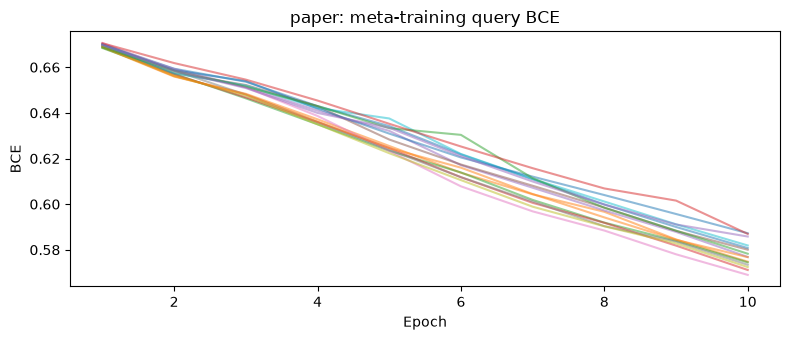

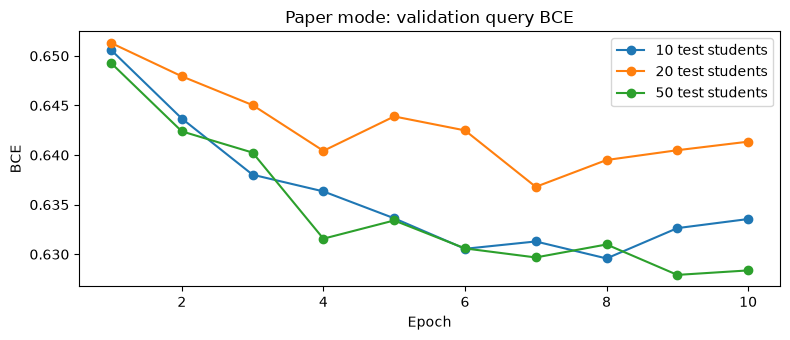

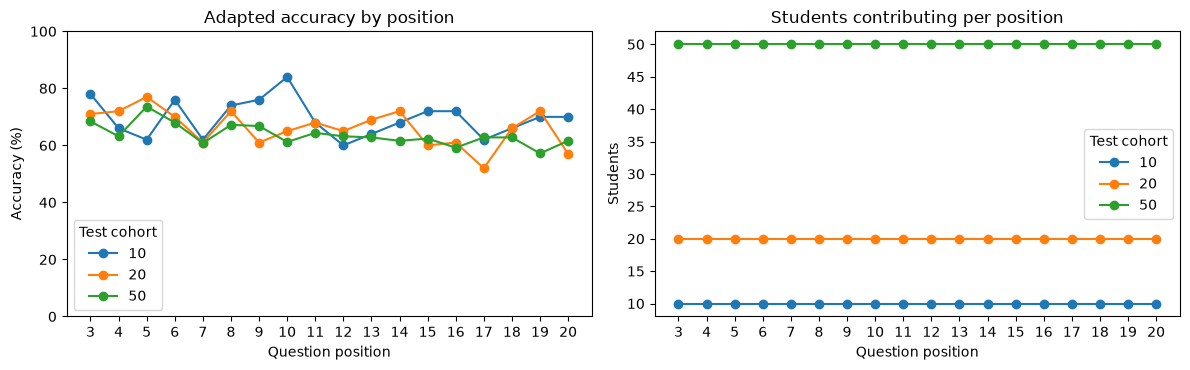

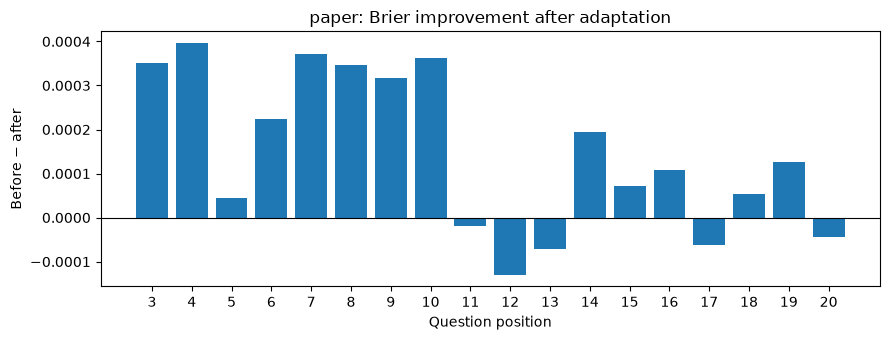

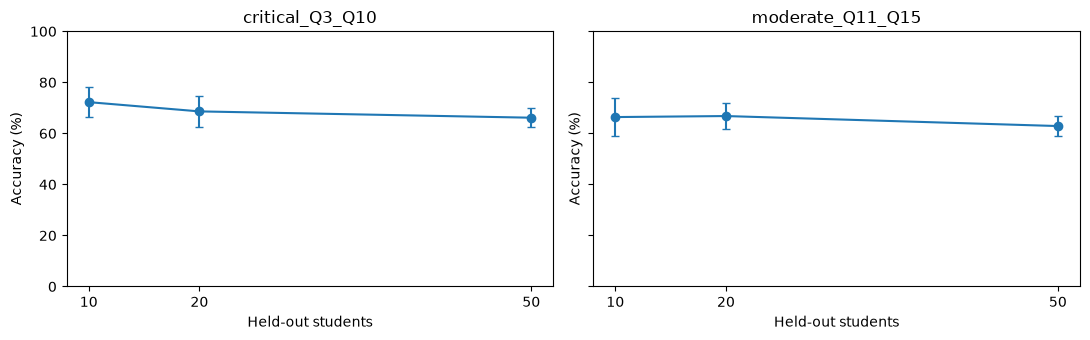

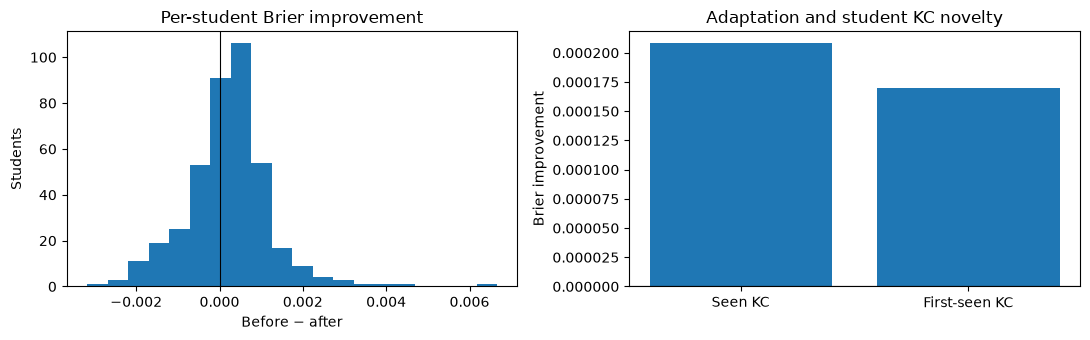

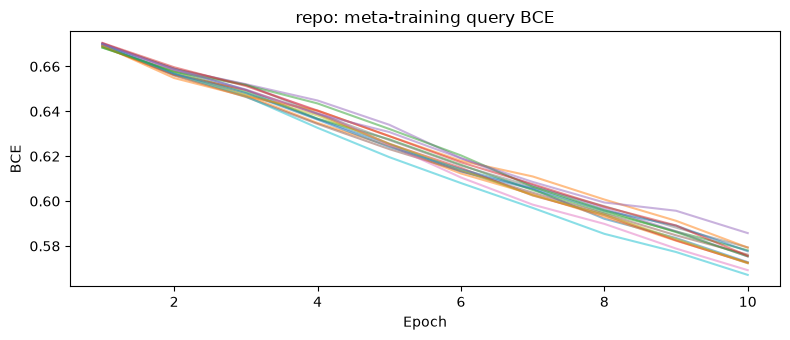

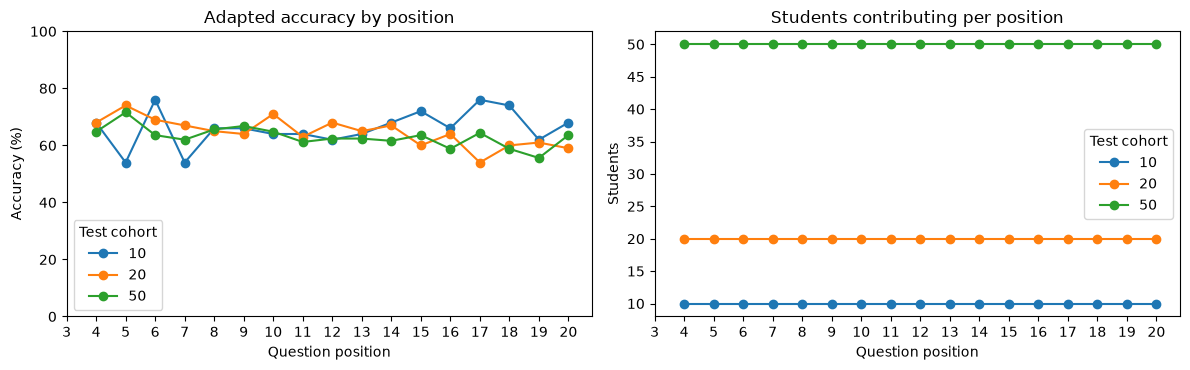

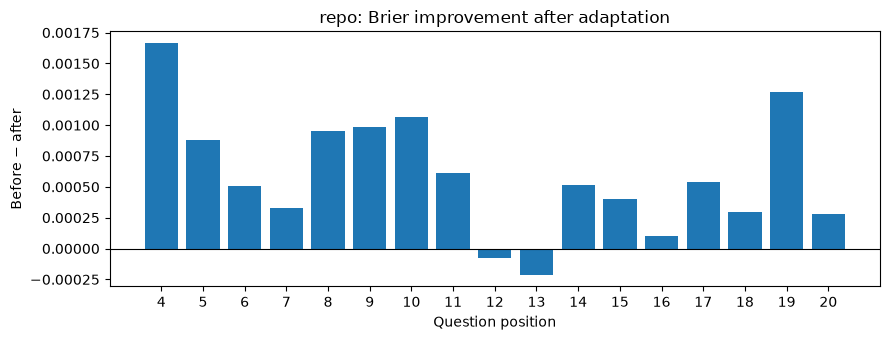

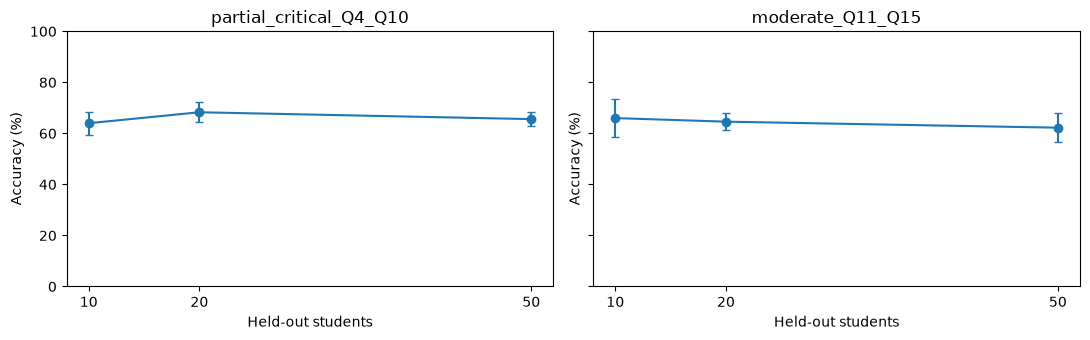

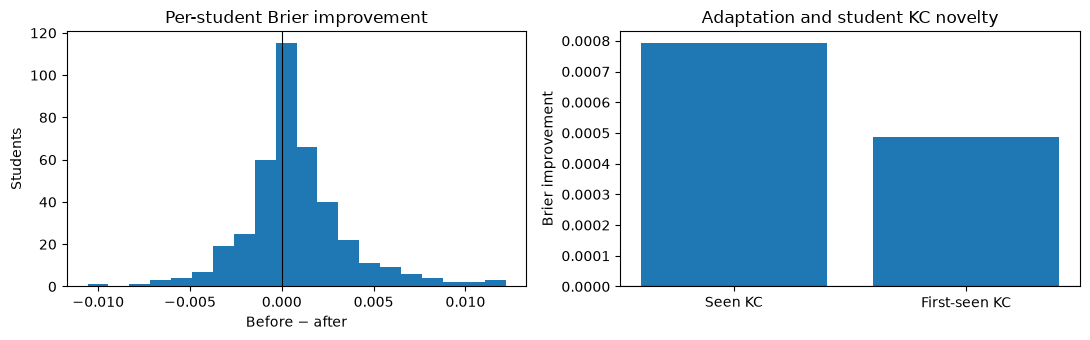

In [12]:
def plot_mode(mode, tables):
    folder = OUTPUT_DIR / mode
    history = tables['history']
    positions = tables['position_results']
    summary = tables['summary']
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for (cohort, split), group in history.groupby(['cohort_size', 'split']):
        ax.plot(group.epoch, group.train_query_bce, alpha=.5, label=f'{cohort} students / split {split}')
    ax.set(title=f'{mode}: meta-training query BCE', xlabel='Epoch', ylabel='BCE')
    fig.tight_layout(); fig.savefig(folder/'training_curves.png', dpi=180); plt.show()

    if mode == 'paper':
        fig, ax = plt.subplots(figsize=(8, 3.5))
        for cohort, group in history.groupby('cohort_size'):
            series = group.groupby('epoch').val_query_bce.mean()
            ax.plot(series.index, series.values, marker='o', label=f'{cohort} test students')
        ax.set(title='Paper mode: validation query BCE', xlabel='Epoch', ylabel='BCE')
        ax.legend(); fig.tight_layout()
        fig.savefig(folder/'validation_curves.png', dpi=180); plt.show()

    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
    for cohort, group in positions.groupby('cohort_size'):
        per_pos = group.groupby('position').agg(acc=('accuracy_after', 'mean'), count=('students', 'mean'))
        axs[0].plot(per_pos.index, 100*per_pos.acc, marker='o', label=str(cohort))
        axs[1].plot(per_pos.index, per_pos['count'], marker='o', label=str(cohort))
    axs[0].set(title='Adapted accuracy by position', xlabel='Question position', ylabel='Accuracy (%)', ylim=(0, 100))
    axs[1].set(title='Students contributing per position', xlabel='Question position', ylabel='Students')
    for ax in axs: ax.legend(title='Test cohort'); ax.set_xticks(range(3, 21))
    fig.tight_layout()
    fig.savefig(folder/'early_position_accuracy_and_counts.png', dpi=180); plt.show()

    fig, ax = plt.subplots(figsize=(9, 3.5))
    per_pos = positions.groupby('position').brier_improvement.mean()
    ax.bar(per_pos.index, per_pos.values)
    ax.axhline(0, color='black', linewidth=.8)
    ax.set(title=f'{mode}: Brier improvement after adaptation', xlabel='Question position', ylabel='Before − after')
    ax.set_xticks(per_pos.index)
    fig.tight_layout(); fig.savefig(folder/'early_brier_improvement.png', dpi=180); plt.show()

    adapted = summary[summary.adaptation.eq('after')]
    primary = 'critical_Q3_Q10' if mode == 'paper' else 'partial_critical_Q4_Q10'
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
    for ax, window in zip(axs, [primary, 'moderate_Q11_Q15']):
        d = adapted[adapted.window.eq(window)].sort_values('cohort_size')
        ax.errorbar(d.cohort_size, 100*d.position_avg_accuracy, yerr=100*d.accuracy_std, marker='o', capsize=3)
        ax.set(title=window, xlabel='Held-out students', ylabel='Accuracy (%)')
        ax.set_xticks(COHORT_SIZES); ax.set_ylim(0, 100)
    fig.tight_layout(); fig.savefig(folder/'window_accuracy_by_cohort.png', dpi=180); plt.show()

    students = tables['student_adaptation']
    kc = tables['kc_diagnostics']
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
    axs[0].hist(students.brier_improvement, bins=20)
    axs[0].axvline(0, color='black', linewidth=.8)
    axs[0].set(title='Per-student Brier improvement', xlabel='Before − after', ylabel='Students')
    kc = kc.assign(weighted_change=kc.brier_improvement*kc.responses)
    by_kc = kc.groupby('new_student_kc')[['weighted_change','responses']].sum()
    by_kc['mean_change'] = by_kc.weighted_change/by_kc.responses
    axs[1].bar(['Seen KC' if not k else 'First-seen KC' for k in by_kc.index], by_kc.mean_change)
    axs[1].axhline(0, color='black', linewidth=.8)
    axs[1].set(title='Adaptation and student KC novelty', ylabel='Brier improvement')
    fig.tight_layout(); fig.savefig(folder/'student_and_kc_diagnostics.png', dpi=180); plt.show()

for mode, result in [('paper', paper_results), ('repo', repo_results)]:
    plot_mode(mode, result)

## 13. Compare protocols on common query positions

Paper mode can predict Q3, while repo mode starts at Q4. We therefore use **Q4–10 and Q11–15** to compare their predictions over the same positions and the same held-out student IDs. Differences include support length, inner steps, and checkpoint selection, so this is a **protocol comparison**, not an isolation of one causal factor.

position_avg_accuracy  pooled_accuracy  \
mode  window           cohort_size                                           
paper common_Q4_Q10    10                          0.7143           0.7143   
                       20                          0.6829           0.6829   
                       50                          0.6583           0.6583   
      moderate_Q11_Q15 10                          0.6640           0.6640   
                       20                          0.6680           0.6680   
                       50                          0.6288           0.6288   
repo  common_Q4_Q10    10                          0.6400           0.6400   
                       20                          0.6829           0.6829   
                       50                          0.6560           0.6560   
      moderate_Q11_Q15 10                          0.6600           0.6600   
                       20                          0.6460           0.6460   
                       50                          0.6224           0.6224   

                                       auc     bce   brier  
mode  window           cohort_size                          
paper common_Q4_Q10    10           0.5943  0.6062  0.2082  
                       20           0.6437  0.6162  0.2130  
                       50           0.5901  0.6387  0.2234  
      moderate_Q11_Q15 10           0.6191  0.6230  0.2164  
                       20           0.6151  0.6364  0.2224  
                       50           0.6055  0.6589  0.2328  
repo  common_Q4_Q10    10           0.5338  0.6219  0.2163  
                       20           0.6580  0.6127  0.2114  
                       50           0.5996  0.6341  0.2212  
      moderate_Q11_Q15 10           0.6315  0.6447  0.2245  
                       20           0.5999  0.6502  0.2287  
                       50           0.6233  0.6528  0.2301

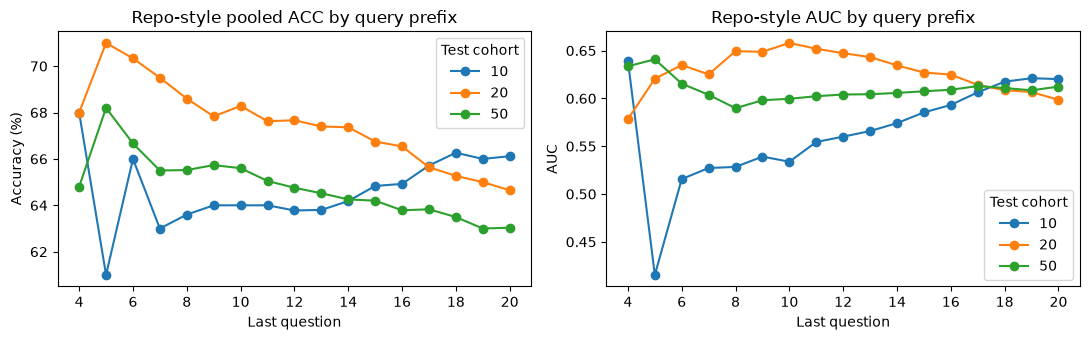

In [ ]:
common_windows = ('common_Q4_Q10', 'moderate_Q11_Q15')
compared = []
for name, tables in [('paper', paper_results), ('repo', repo_results)]:
    selected = tables['split_results']
    selected = selected[selected.window.isin(common_windows) & selected.adaptation.eq('after')]
    compared.append(selected.assign(mode=name))
comparison = pd.concat(compared, ignore_index=True)
comparison.to_csv(OUTPUT_DIR/'mode_comparison.csv', index=False)
display(comparison.groupby(['mode', 'window', 'cohort_size'])[['position_avg_accuracy', 'pooled_accuracy', 'auc', 'bce', 'brier']].mean().round(4))

repo_prefix = repo_results['prefix_metrics']
repo_prefix = repo_prefix[repo_prefix.adaptation.eq('after')]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
for cohort, group in repo_prefix.groupby('cohort_size'):
    d = group.groupby('end_position')[['pooled_accuracy', 'auc']].mean()
    axs[0].plot(d.index, 100*d.pooled_accuracy, marker='o', label=str(cohort))
    axs[1].plot(d.index, d.auc, marker='o', label=str(cohort))
axs[0].set(title='Repo-style pooled ACC by query prefix', xlabel='Last question', ylabel='Accuracy (%)')
axs[1].set(title='Repo-style AUC by query prefix', xlabel='Last question', ylabel='AUC')
for ax in axs: ax.legend(title='Test cohort')
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'repo/repo_prefix_accuracy_auc.png', dpi=180)
plt.show()

## 14. Reference values and reproduction status

The paper reports MAML accuracy for each ASSIST2009 cohort and five sets. We compare those numbers descriptively with our **paper-style** cohorts only: our random student identities and preprocessing are not verified to match theirs. The repo-style Q4–10 window cannot be compared directly with the paper's full Q3–10 window.

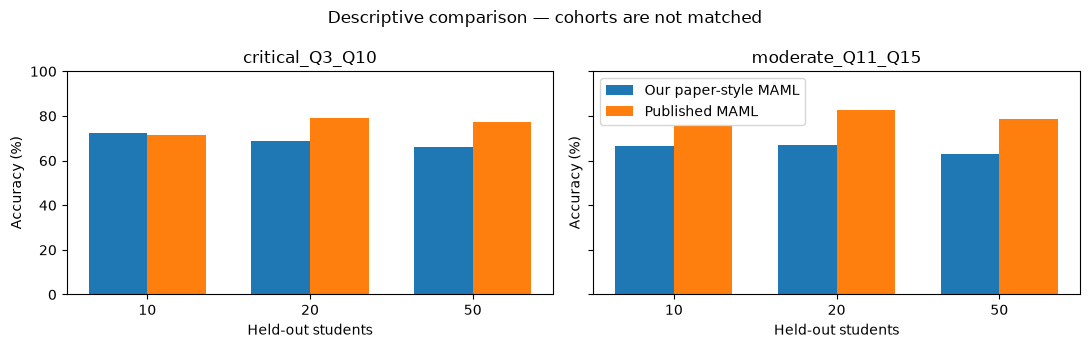

Results: C:\Users\Dell ProMax Tower T2\Downloads\code\kt-state-lab\outputs\maml\ASSISTment2009
Paper style: C:\Users\Dell ProMax Tower T2\Downloads\code\kt-state-lab\outputs\maml\ASSISTment2009\paper
Repo style: C:\Users\Dell ProMax Tower T2\Downloads\code\kt-state-lab\outputs\maml\ASSISTment2009\repo


In [14]:
published = {
    (10, 'critical_Q3_Q10'): [75.3, 75.9, 72.3, 67.2, 66.8],
    (20, 'critical_Q3_Q10'): [81.1, 76.8, 81.0, 75.5, 81.9],
    (50, 'critical_Q3_Q10'): [80.1, 77.8, 74.4, 77.1, 77.5],
    (10, 'moderate_Q11_Q15'): [79.4, 78.1, 76.6, 71.9, 70.5],
    (20, 'moderate_Q11_Q15'): [82.6, 80.9, 82.7, 82.0, 84.6],
    (50, 'moderate_Q11_Q15'): [85.0, 78.4, 72.0, 79.6, 77.2]
}
reference = pd.DataFrame([{'cohort_size': cohort, 'window': window,
    'published_accuracy': np.mean(values)/100}
    for (cohort, window), values in published.items()])
ours = paper_results['summary']
ours = ours[ours.adaptation.eq('after')][['cohort_size', 'window', 'position_avg_accuracy']]
reference = ours.merge(reference, on=['cohort_size', 'window'])
reference.to_csv(OUTPUT_DIR/'paper/published_reference_comparison.csv', index=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, window in zip(axs, ['critical_Q3_Q10', 'moderate_Q11_Q15']):
    d = reference[reference.window.eq(window)].sort_values('cohort_size')
    x = np.arange(len(d))
    ax.bar(x-.18, 100*d.position_avg_accuracy, width=.36, label='Our paper-style MAML')
    ax.bar(x+.18, 100*d.published_accuracy, width=.36, label='Published MAML')
    ax.set_xticks(x, [str(cohort) for cohort in d.cohort_size])
    ax.set(title=window, xlabel='Held-out students', ylabel='Accuracy (%)', ylim=(0, 100))
axs[1].legend()
fig.suptitle('Descriptive comparison — cohorts are not matched')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'paper/published_maml_reference.png', dpi=180);plt.show()

print('Results:', OUTPUT_DIR)
print('Paper style:', OUTPUT_DIR/'paper')
print('Repo style:', OUTPUT_DIR/'repo')

## 15. What these experiments establish

Both modes run on the **same independent, randomly sampled cohorts** for every size and split. A split's test students are entirely absent from its meta-training and validation sets. Within a held-out student's sequence, adaptation uses only the early support answers; later answer labels are used only to score predictions. Later query responses may enter the GRU as history **after** their own predictions, without further parameter updates.

**Paper-style results** can be reported for the full Q3–10 and Q11–15 windows. **Repo-style results** use Q4–10, Q11–15, pooled ACC/AUC, and cumulative Q4–Q20 prefixes. The authors' processed test cohorts, preprocessing, and exact paper hyperparameter search are still separate reproduction tasks.

`outputs/maml/ASSISTment2009/eda/` contains shared EDA; `paper/` and `repo/` each contain their own per-cohort/split training outputs and figures. A Run All trains **30 models** (3 cohort sizes × 5 splits × 2 protocols) with 10 epochs each, so it is computationally substantial.